# Exploring the Fireworks Galaxy
**Mithul Sourav · CFAL Astronomy Club**

I started this as a school astronomy project to see what I could learn from a calibrated Hubble image of NGC 6946. This restored version keeps the original observation, the wide-to-nucleus comparison, and the Sato and Meijering filters. It adds the missing literature survey and data checks, and it runs without a Google Drive mount.

Open this notebook in Google Colab or Jupyter and run the cells in order. If any package is missing, install it in a notebook cell with `%pip install "astropy>=6,<8" "scipy>=1.13,<2" "matplotlib>=3.8,<4" "scikit-image>=0.23,<1"`. The data cell uses a local copy of the FITS file when present and otherwise downloads the public exposure from MAST.

## 1. Literature survey · NGC 4826

I picked the Black Eye Galaxy as the comparison target. It appears in the same NICMOS survey of galaxy centres as NGC 6946.

1. **The galaxy.** NGC 4826 (Messier 64) is a spiral galaxy in Coma Berenices. [NASA/Hubble overview](https://science.nasa.gov/missions/hubble/hubble-looks-at-a-a-black-eye-galaxy/).
2. **Galactic coordinates.** Its Galactic longitude is **315.681974°**, and its Galactic latitude is **+84.422965°**. [SIMBAD](https://simbad.u-strasbg.fr/simbad/sim-id?Ident=NGC+4826).
3. **What stands out.** An asymmetric dust band crosses one side of the bright centre and gives the galaxy its name. [NASA/Hubble](https://science.nasa.gov/missions/hubble/hubble-looks-at-a-a-black-eye-galaxy/).
4. **Previous work.** H I observations show that the inner and outer gas disks rotate in opposite directions. Hubble's NICMOS survey also imaged the central region in the infrared. [H I kinematics](https://ntrs.nasa.gov/search.jsp?R=19950033121) · [NICMOS survey](https://arxiv.org/abs/astro-ph/9903307) · [NGC 4826 survey image](https://esahubble.org/images/opo9910f/).
5. **Hypothesis.** If extinction causes most of the dark band's contrast, it should look weaker in a near-infrared image than in a visible image. I would align images of the same field, match their effective resolution, and compare the dust-lane brightness with nearby areas in both bands. The analysis below uses NGC 6946, so this comparison remains a proposed test.

## 2. Explore the calibrated NGC 6946 frame

The original notebook points to `n4k48nbsq_cal.fits`, a calibrated Hubble NICMOS F160W exposure from [HST program 7919](https://arxiv.org/abs/astro-ph/9903307). The [NICMOS data guide](https://www.stsci.edu/instruments/nicmos/documents/handbooks/instrument/v5/c11_pipeline4.html) describes the science, error, quality, sample-count, and integration-time arrays.

For this image I want to check whether the bright centre is present in the unfiltered data and whether its position agrees with the catalogue. I use the [SIMBAD infrared position](https://simbad.cds.unistra.fr/simbad/sim-basic?Ident=NGC+6946) and the FITS world coordinate system (WCS) to place the cutouts.

In [1]:
from pathlib import Path
from hashlib import sha256

import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, ListedColormap
from matplotlib.patches import Rectangle
from IPython.display import Image, display
from astropy import units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.utils.data import download_file
from astropy.visualization import AsinhStretch, ImageNormalize
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales
from scipy.ndimage import distance_transform_edt
from skimage.filters import sato, meijering

FILENAME = "n4k48nbsq_cal.fits"
MAST_URL = "https://mast.stsci.edu/api/v0.1/Download/file?uri=mast%3AHST%2Fproduct%2Fn4k48nbsq_cal.fits"
local_fits = Path(FILENAME)
fits_path = local_fits if local_fits.is_file() else Path(download_file(MAST_URL, cache=True, timeout=90))

with fits.open(fits_path, memmap=False) as exposure:
    print("FITS planes:", ", ".join(hdu.name for hdu in exposure))
    primary = exposure[0].header.copy()
    science_header = exposure["SCI"].header.copy()
    science = exposure["SCI"].data.astype(float)
    dq = exposure["DQ"].data.copy()

expected = {"ROOTNAME": "n4k48nbsq", "TARGNAME": "NGC6946", "INSTRUME": "NICMOS", "FILTER": "F160W"}
for keyword, value in expected.items():
    if str(primary.get(keyword, "")).strip() != value:
        raise ValueError(f"Expected {keyword}={value} in {FILENAME}")
if science.shape != (256, 256) or dq.shape != science.shape:
    raise ValueError("Unexpected SCI or DQ array dimensions.")

print(f"{primary['DATE-OBS']} · program {primary['PROPOSID']} · {primary['EXPTIME']:.2f} s")
print(f"SCI unit: {science_header['BUNIT']}")
print(f"FITS SHA-256: {sha256(fits_path.read_bytes()).hexdigest()}")

FITS planes: PRIMARY, SCI, ERR, DQ, SAMP, TIME
1998-01-19 · program 7919 · 191.96 s
SCI unit: COUNTS/S
FITS SHA-256: ca25d54362ffad5c14f3d815b0026d01db714e2f8fa81742ac98b8080dba28a1


In [2]:
valid = np.isfinite(science) & (dq == 0)
if not valid.any():
    raise ValueError("The quality mask leaves no finite science pixels.")

catalogue = SkyCoord("20h34m52.332s", "+60d09m13.24s", frame="icrs")
wcs = WCS(science_header).celestial
cx, cy = map(float, wcs.world_to_pixel(catalogue))
if not (0 <= cx < science.shape[1] and 0 <= cy < science.shape[0]):
    raise ValueError("The catalogued centre falls outside the detector image.")
pixel_scale = float(np.mean(proj_plane_pixel_scales(wcs)) * 3600)
peak_y, peak_x = np.unravel_index(np.argmax(np.where(valid, science, -np.inf)), science.shape)
separation = wcs.pixel_to_world(peak_x, peak_y).separation(catalogue).arcsec

yy, xx = np.indices(science.shape)
radius = np.hypot(xx - cx, yy - cy)
p02, median, p98, p995, p9995 = np.percentile(science[valid], [2, 50, 98, 99.5, 99.95])
core = float(np.median(science[valid & (radius < 5)]))
outer = float(np.median(science[valid & (radius >= 30) & (radius < 60)]))
print(f"Pixels used: {valid.sum():,} / {science.size:,} ({valid.mean():.2%})")
print(f"Median: {median:.2f} counts/s · 98th percentile: {p98:.2f} counts/s")
print(f"Catalogue centre at detector (x, y) = ({cx:.2f}, {cy:.2f}); scale ≈ {pixel_scale:.3f} arcsec/pixel")
print(f"Brightest usable pixel (x, y) = ({peak_x}, {peak_y}); catalogue separation = {separation:.2f} arcsec")
print(f"Median in r < 5 pixels: {core:.2f} counts/s; in 30 ≤ r < 60: {outer:.2f} counts/s")

Pixels used: 65,045 / 65,536 (99.25%)
Median: 1.96 counts/s · 98th percentile: 11.24 counts/s
Catalogue centre at detector (x, y) = (139.94, 206.73); scale ≈ 0.203 arcsec/pixel
Brightest usable pixel (x, y) = (141, 205); catalogue separation = 0.41 arcsec
Median in r < 5 pixels: 55.58 counts/s; in 30 ≤ r < 60: 4.15 counts/s


### Five things I learned from the data

1. This is one central field from 19 January 1998 in the F160W near-infrared band. The calibrated science plane is **256 × 256** and stores a count rate.
2. The quality mask keeps **65,045 of 65,536 pixels**. I exclude flagged pixels from the statistics and mark them in blue-grey in the images. A cluster of flags overlaps the bright centre, so the median describes the usable pixels in each ring.
3. The count rates are strongly skewed. The median is **1.96 counts/s**, while the 98th percentile is **11.24 counts/s**. A stretch helps show the faint field and the bright centre together.
4. The catalogue centre falls near **(140, 207)** in zero-based detector coordinates. The brightest usable pixel is about **0.41 arcseconds** away, so the brightest area is close to the independently catalogued centre.
5. The median rises from **4.15 counts/s** in the 30–60 pixel annulus to **55.58 counts/s** inside five pixels of the centre. The central brightening is already visible in the calibrated image.

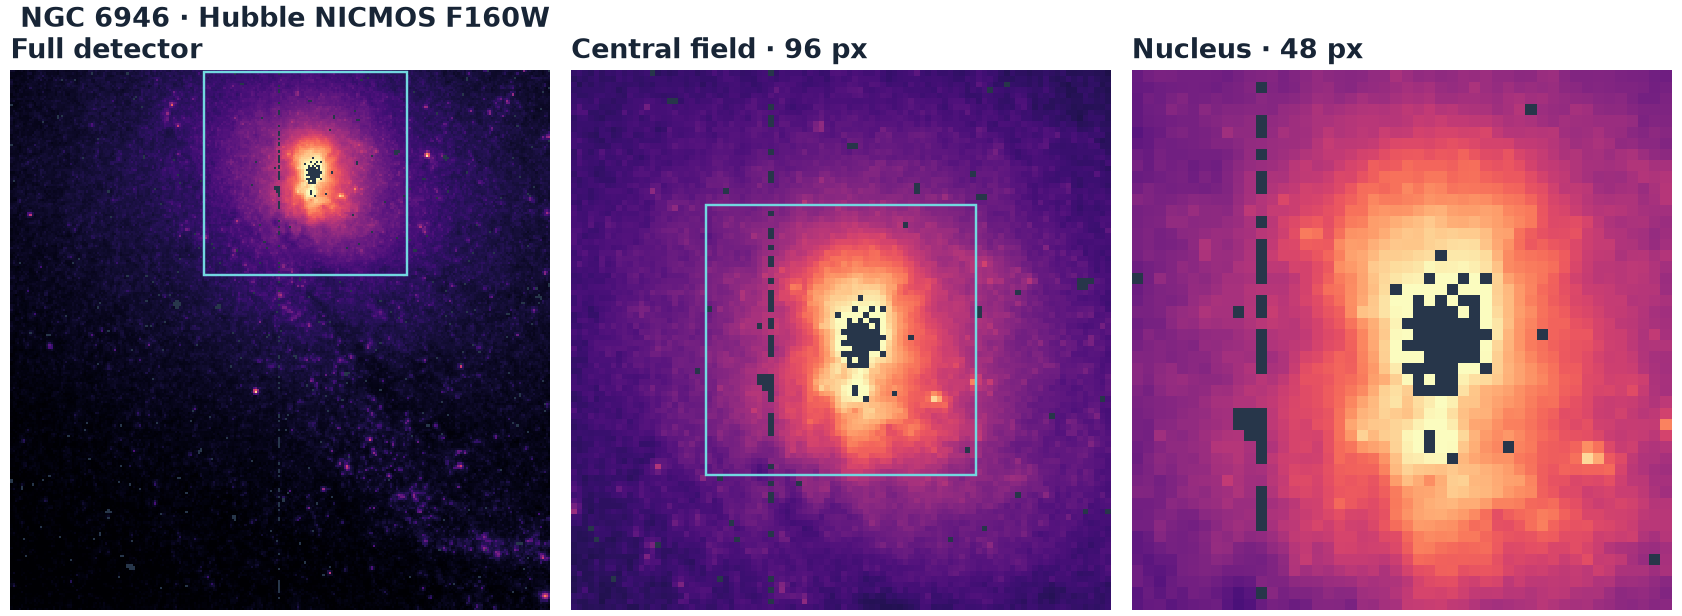

In [3]:
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
INK, BLUE, GRAY = "#182536", "#255976", "#687588"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11, "text.color": INK,
    "axes.labelcolor": INK, "axes.titlecolor": INK, "axes.spines.top": False,
    "axes.spines.right": False, "figure.facecolor": "white",
})

def save_figure(fig, name):
    path = FIGURES / name
    fig.savefig(path, dpi=145, facecolor=fig.get_facecolor())
    plt.close(fig)
    display(Image(filename=str(path)))

def cutout(half_width):
    x, y = round(cx), round(cy)
    return (
        slice(max(y - half_width, 0), min(y + half_width, science.shape[0])),
        slice(max(x - half_width, 0), min(x + half_width, science.shape[1])),
    )

wide, nucleus = cutout(48), cutout(24)
intensity = ImageNormalize(vmin=p02, vmax=p9995, stretch=AsinhStretch(a=0.035), clip=True)
stretched_science = np.ma.array(intensity(science), mask=~valid)
field_cmap = plt.colormaps["magma"].with_extremes(bad="#27364a")

fig, axes = plt.subplots(1, 3, figsize=(11.6, 4.25), layout="constrained")
for ax, image, title in zip(
    axes, (stretched_science, stretched_science[wide], stretched_science[nucleus]),
    ("Full detector", "Central field · 96 px", "Nucleus · 48 px")
):
    ax.imshow(image, origin="lower", cmap=field_cmap, vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_axis_off()
for ax, region, next_region in ((axes[0], None, wide), (axes[1], wide, nucleus)):
    y0, x0 = (0, 0) if region is None else (region[0].start, region[1].start)
    dy, dx = next_region
    ax.add_patch(Rectangle(
        (dx.start - x0 - 0.5, dy.start - y0 - 0.5),
        dx.stop - dx.start, dy.stop - dy.start,
        edgecolor="#72d8e0", linewidth=1.2, fill=False,
    ))
fig.suptitle("NGC 6946 · Hubble NICMOS F160W", x=0.012, ha="left", fontweight="bold")
save_figure(fig, "fireworks-field.png")

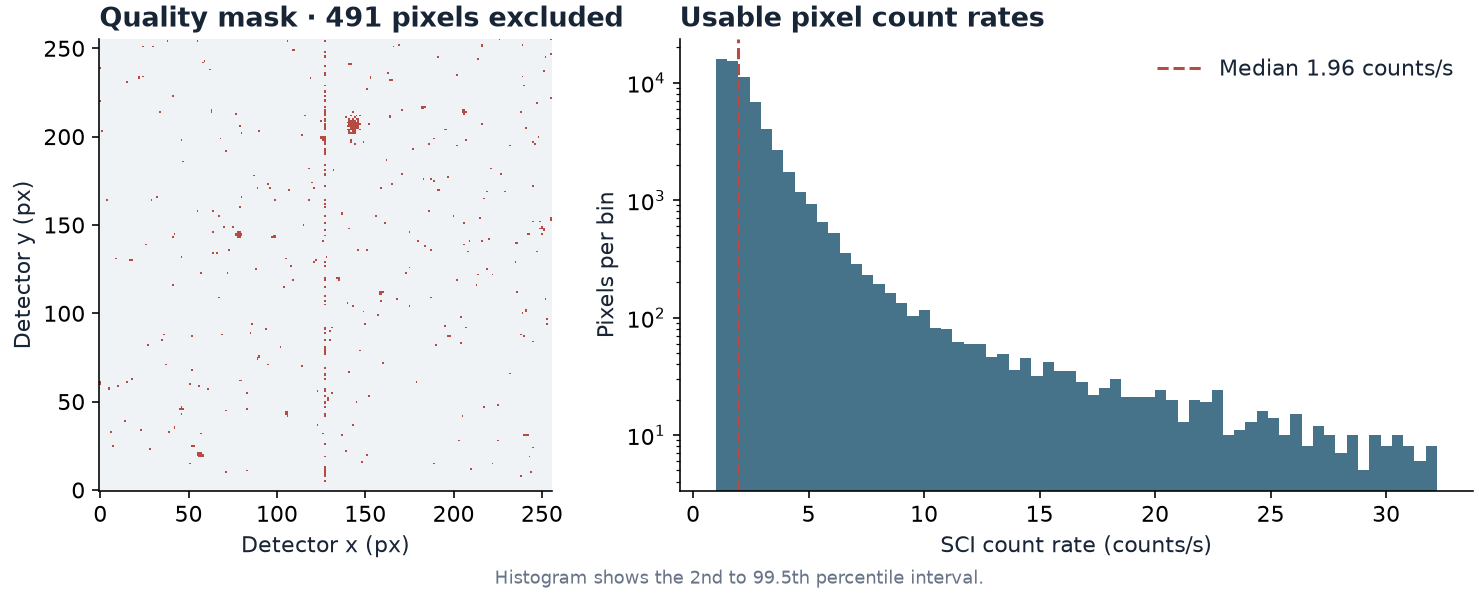

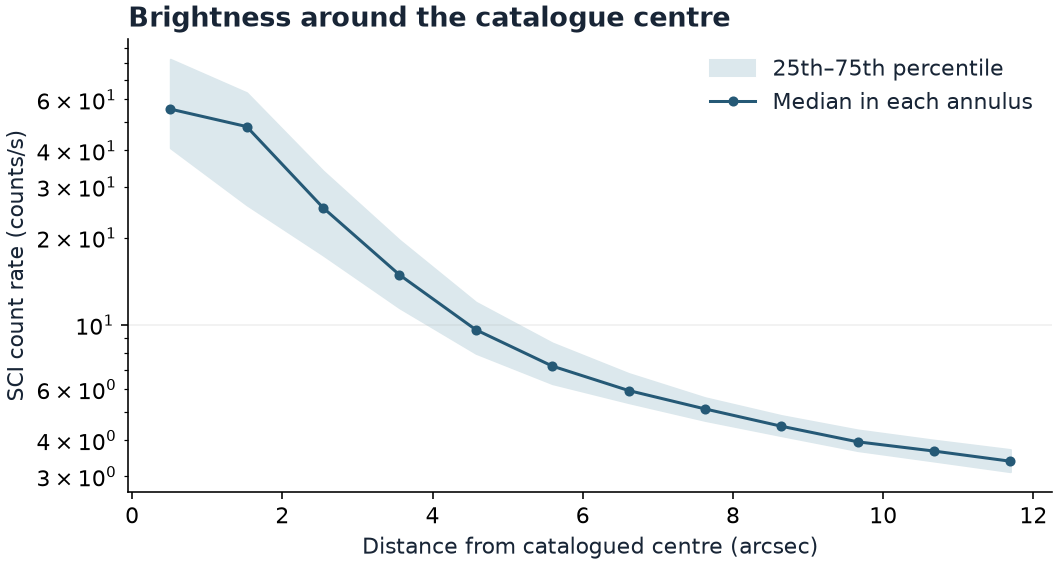

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.1), layout="constrained", gridspec_kw={"width_ratios": [1, 1.55]})
axes[0].imshow(~valid, origin="lower", cmap=ListedColormap(["#eff3f5", "#b74b43"]), interpolation="nearest")
axes[0].set_title(f"Quality mask · {(~valid).sum()} pixels excluded", loc="left", fontweight="bold")
axes[0].set_xlabel("Detector x (px)")
axes[0].set_ylabel("Detector y (px)")
axes[1].hist(science[valid], bins=np.linspace(p02, p995, 65), color=BLUE, alpha=0.85)
axes[1].axvline(median, color="#b74b43", linestyle="--", label=f"Median {median:.2f} counts/s")
axes[1].set_yscale("log")
axes[1].set_title("Usable pixel count rates", loc="left", fontweight="bold")
axes[1].set_xlabel("SCI count rate (counts/s)")
axes[1].set_ylabel("Pixels per bin")
axes[1].legend(frameon=False)
fig.supxlabel("Histogram shows the 2nd to 99.5th percentile interval.", color=GRAY, fontsize=9)
save_figure(fig, "fireworks-quality.png")

edges = np.arange(0, 61, 5)
rings = [science[valid & (radius >= lo) & (radius < hi)] for lo, hi in zip(edges[:-1], edges[1:])]
quartiles = np.array([np.percentile(ring, [25, 50, 75]) for ring in rings])
distance = (edges[:-1] + edges[1:]) * 0.5 * pixel_scale
fig, ax = plt.subplots(figsize=(7.3, 3.9), layout="constrained")
ax.fill_between(distance, quartiles[:, 0], quartiles[:, 2], color="#dce8ed", label="25th–75th percentile")
ax.plot(distance, quartiles[:, 1], "o-", color=BLUE, markersize=4, label="Median in each annulus")
ax.set(yscale="log", xlabel="Distance from catalogued centre (arcsec)", ylabel="SCI count rate (counts/s)")
ax.set_title("Brightness around the catalogue centre", loc="left", fontweight="bold")
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)
save_figure(fig, "fireworks-profile.png")

## 3. Try two filters and five colormaps

The original notebook explored Sato and Meijering. Both use local curvature to emphasize narrow, elongated features. I set both to look for bright ridges and use the same scales of 1, 2, and 4 pixels. I filter the full frame before cropping to avoid making new filter edges at each cutout boundary. For filtering only, each masked pixel takes the nearest usable value. I mask those pixels again in the outputs. Features around gaps and image borders still need care. [scikit-image filter documentation](https://scikit-image.org/docs/0.26.x/api/skimage.filters.html).

The five palettes are grayscale, hot, magma, viridis, and cividis. Each row uses one fixed normalization for all five palettes. The two filter rows show scaled ridge response, while the first row shows stretched science data.

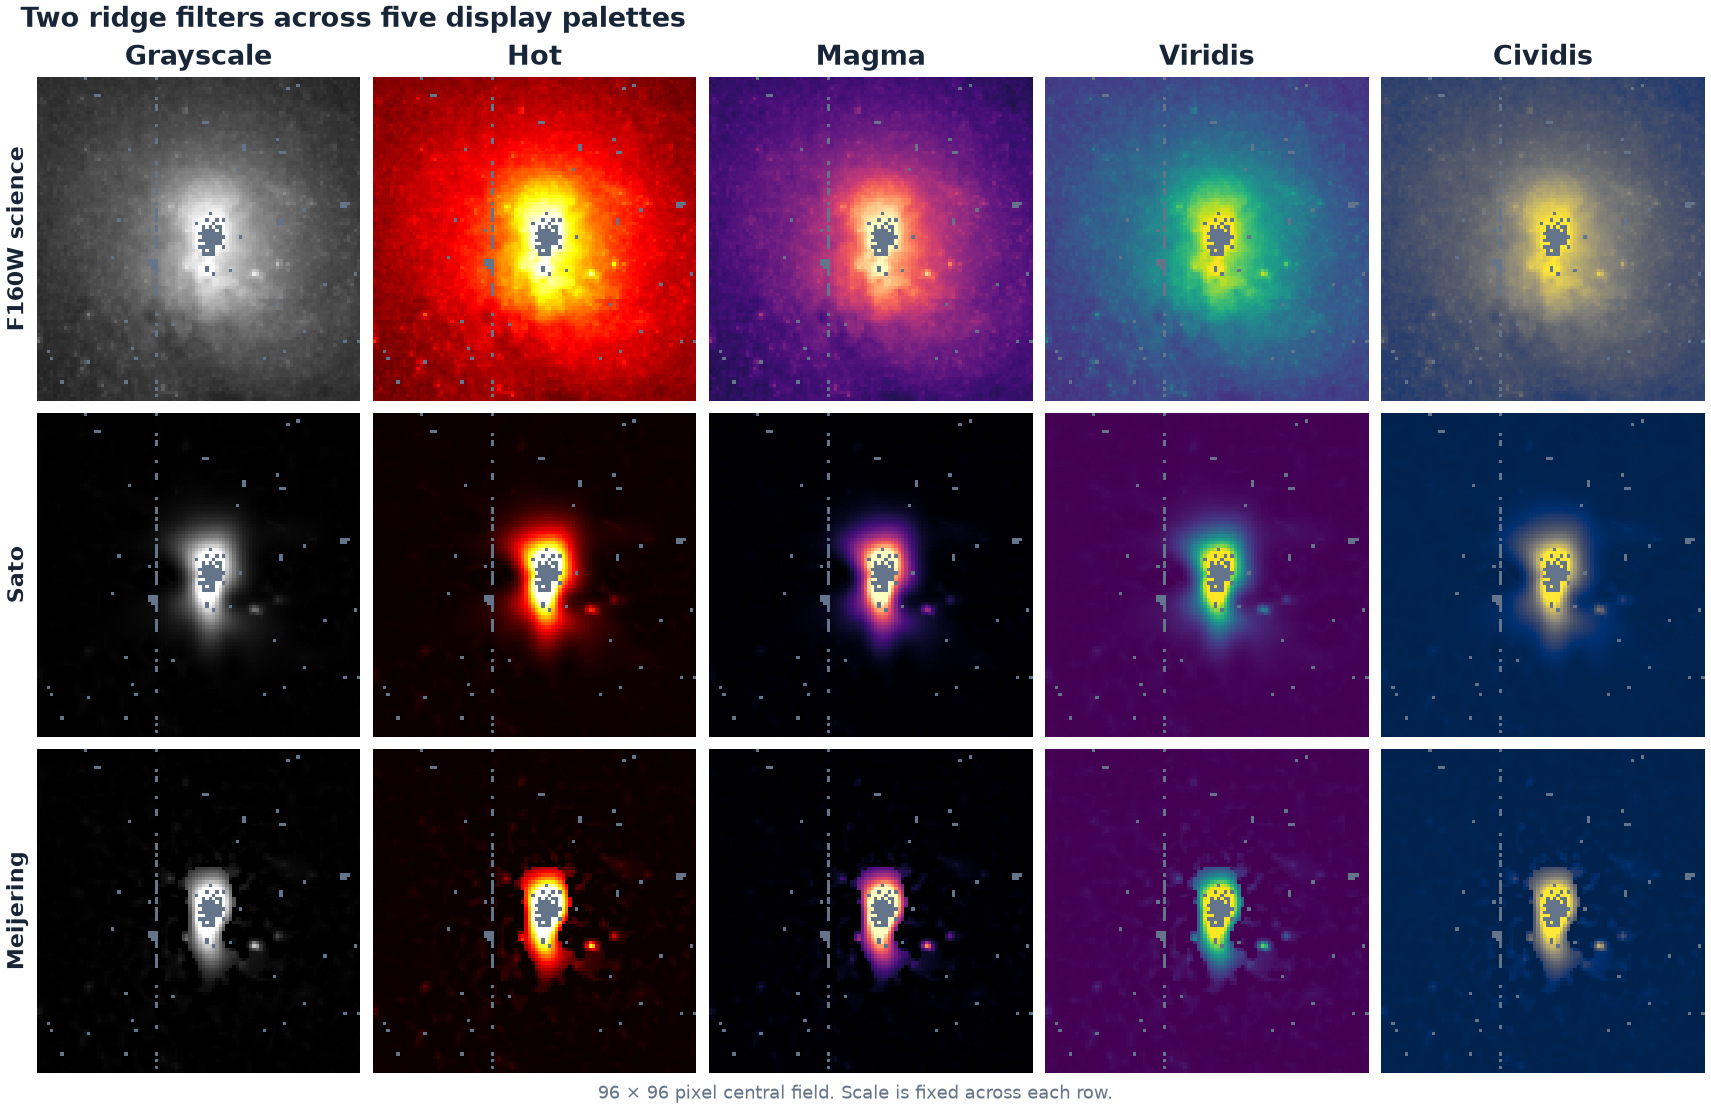

In [5]:
nearest_y, nearest_x = distance_transform_edt(~valid, return_distances=False, return_indices=True)
filled = science[nearest_y, nearest_x]
working = (filled - median) / (p995 - median)
scales = (1, 2, 4)
ridge_maps = {
    "Sato": sato(working, sigmas=scales, black_ridges=False),
    "Meijering": meijering(working, sigmas=scales, black_ridges=False),
}

def scale_response(response):
    ceiling = np.percentile(response[wide][valid[wide]], 99.5)
    if not np.isfinite(ceiling) or ceiling <= 0:
        raise ValueError("Ridge response has no positive display range.")
    return Normalize(vmin=0, vmax=ceiling, clip=True)(np.ma.array(response, mask=~valid))

panels = {
    "F160W science": stretched_science[wide],
    **{name: scale_response(response)[wide] for name, response in ridge_maps.items()},
}
palettes = ("gray", "hot", "magma", "viridis", "cividis")
fig, axes = plt.subplots(3, 5, figsize=(11.8, 7.65), layout="constrained")
for row, (name, panel) in enumerate(panels.items()):
    for col, palette in enumerate(palettes):
        ax = axes[row, col]
        cmap = plt.colormaps[palette].with_extremes(bad="#64748b")
        ax.imshow(panel, origin="lower", cmap=cmap, vmin=0, vmax=1, interpolation="nearest")
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if row == 0:
            ax.set_title("Grayscale" if palette == "gray" else palette.title(), fontweight="bold")
        if col == 0:
            ax.set_ylabel(name, fontweight="bold")
fig.suptitle("Two ridge filters across five display palettes", x=0.012, ha="left", fontweight="bold")
fig.supxlabel("96 × 96 pixel central field. Scale is fixed across each row.", color=GRAY, fontsize=9)
save_figure(fig, "fireworks-filters.png")

### What changed across the displays

1. **Filters.** The bright central feature is present before filtering. Sato gives a broader response around the bright centre, while Meijering concentrates the strongest response more tightly. I check features against the F160W image and look at the quality mask before interpreting structure near flagged pixels.
2. **Colormaps.** Grayscale makes the original brightness easy to read. Cividis and viridis separate nearby response levels without changing the values. The palette changes what stands out to the eye, so I keep the stretch fixed across a row.
3. **My choice.** I would start with the unfiltered magma panel for context, then use Sato in cividis to inspect fine structure. The radial profile and catalogue alignment are the evidence for the central brightening. The ridge maps are visual guides, and identifying the source of that light would require additional observations.

Data credit: NASA/ESA Hubble Space Telescope, NICMOS, via the Mikulski Archive for Space Telescopes. The survey is described in [Böker et al. (1999)](https://arxiv.org/abs/astro-ph/9903307).